In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ast

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [17]:
print("Libraries imported successfully!")

Libraries imported successfully!


In [18]:
from google.colab import files
uploaded = files.upload()

In [19]:
ratings = pd.read_csv("ratings_small.csv")
movies = pd.read_csv("movies_metadata.csv", low_memory=False)
links = pd.read_csv("links_small.csv")
print("Datasets loaded successfully!")

Datasets loaded successfully!


In [20]:
display(ratings.head())
display(movies.head())
display(links.head())

,userId,movieId,rating,timestamp
0,1,31,2.5,1260759144
1,1,1029,3.0,1260759179
2,1,1061,3.0,1260759182
3,1,1129,2.0,1260759185
4,1,1172,4.0,1260759205


,adult,belongs_to_collection,budget,genres,homepage,id,imdb_id,original_language,original_title,overview,...,release_date,revenue,runtime,spoken_languages,status,tagline,title,video,vote_average,vote_count
0,False,"{'id': 10194, 'name': 'Toy Story Collection', ...",30000000,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '...",http://toystory.disney.com/toy-story,862,tt0114709,en,Toy Story,"Led by Woody, Andy's toys live happily in his ...",...,1995-10-30,373554033.0,81.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,NaN,Toy Story,False,7.7,5415.0
1,False,NaN,65000000,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...",NaN,8844,tt0113497,en,Jumanji,When siblings Judy and Peter discover an encha...,...,1995-12-15,262797249.0,104.0,"[{'iso_639_1': 'en', 'name': 'English'}, {'iso...",Released,Roll the dice and unleash the excitement!,Jumanji,False,6.9,2413.0
2,False,"{'id': 119050, 'name': 'Grumpy Old Men Collect...",0,"[{'id': 10749, 'name': 'Romance'}, {'id': 35, ...",NaN,15602,tt0113228,en,Grumpier Old Men,A family wedding reignites the ancient feud be...,...,1995-12-22,0.0,101.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Still Yelling. Still Fighting. Still Ready for...,Grumpier Old Men,False,6.5,92.0
3,False,NaN,16000000,"[{'id': 35, 'name': 'Comedy'}, {'id': 18, 'nam...",NaN,31357,tt0114885,en,Waiting to Exhale,"Cheated on, mistreated and stepped on, the wom...",...,1995-12-22,81452156.0,127.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Friends are the people who let you be yourself...,Waiting to Exhale,False,6.1,34.0
4,False,"{'id': 96871, 'name': 'Father of the Bride Col...",0,"[{'id': 35, 'name': 'Comedy'}]",NaN,11862,tt0113041,en,Father of the Bride Part II,Just when George Banks has recovered from his ...,...,1995-02-10,76578911.0,106.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Just When His World Is Back To Normal... He's ...,Father of the Bride Part II,False,5.7,173.0


,movieId,imdbId,tmdbId
0,1,114709,862.0
1,2,113497,8844.0
2,3,113228,15602.0
3,4,114885,31357.0
4,5,113041,11862.0


In [21]:
print("Ratings Information:")
print(ratings.info())

Ratings Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100004 entries, 0 to 100003
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   userId     100004 non-null  int64  
 1   movieId    100004 non-null  int64  
 2   rating     100004 non-null  float64
 3   timestamp  100004 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 3.1 MB
None


In [22]:
print("\nMovies Information:")
print(movies.info())


Movies Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45466 entries, 0 to 45465
Data columns (total 24 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   adult                  45466 non-null  object 
 1   belongs_to_collection  4494 non-null   object 
 2   budget                 45466 non-null  object 
 3   genres                 45466 non-null  object 
 4   homepage               7782 non-null   object 
 5   id                     45466 non-null  object 
 6   imdb_id                45449 non-null  object 
 7   original_language      45455 non-null  object 
 8   original_title         45466 non-null  object 
 9   overview               44512 non-null  object 
 10  popularity             45461 non-null  object 
 11  poster_path            45080 non-null  object 
 12  production_companies   45463 non-null  object 
 13  production_countries   45463 non-null  object 
 14  release_date           45379 non-

In [23]:
print("\nRatings Shape:", ratings.shape)
print("Movies Shape:", movies.shape)


Ratings Shape: (100004, 4)
Movies Shape: (45466, 24)


In [24]:
print("Missing values in ratings:")
print(ratings.isnull().sum())

Missing values in ratings:
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64


In [25]:
print("\nMissing values in movies:")
print(movies.isnull().sum())


Missing values in movies:
adult                        0
belongs_to_collection    40972
budget                       0
genres                       0
homepage                 37684
id                           0
imdb_id                     17
original_language           11
original_title               0
overview                   954
popularity                   5
poster_path                386
production_companies         3
production_countries         3
release_date                87
revenue                      6
runtime                    263
spoken_languages             6
status                      87
tagline                  25054
title                        6
video                        6
vote_average                 6
vote_count                   6
dtype: int64


In [26]:
ratings = ratings.dropna()
ratings = ratings.drop_duplicates()

movies = movies.drop_duplicates()

print("Data cleaning completed!")

Data cleaning completed!


In [27]:
movies['id'] = pd.to_numeric(movies['id'], errors='coerce')
links['tmdbId'] = pd.to_numeric(links['tmdbId'], errors='coerce')

In [28]:
merged = ratings.merge(links, on='movieId', how='left')

merged = merged.merge(
    movies[['id', 'title', 'genres']],
    left_on='tmdbId',
    right_on='id',
    how='left'
)

print("Merged dataset:")
display(merged.head())

Merged dataset:


,userId,movieId,rating,timestamp,imdbId,tmdbId,id,title,genres
0,1,31,2.5,1260759144,112792,9909.0,9909.0,Dangerous Minds,"[{'id': 18, 'name': 'Drama'}, {'id': 80, 'name..."
1,1,1029,3.0,1260759179,33563,11360.0,11360.0,Dumbo,"[{'id': 16, 'name': 'Animation'}, {'id': 10751..."
2,1,1061,3.0,1260759182,117665,819.0,819.0,Sleepers,"[{'id': 80, 'name': 'Crime'}, {'id': 18, 'name..."
3,1,1129,2.0,1260759185,82340,1103.0,1103.0,Escape from New York,"[{'id': 878, 'name': 'Science Fiction'}, {'id'..."
4,1,1172,4.0,1260759205,95765,11216.0,11216.0,Cinema Paradiso,"[{'id': 18, 'name': 'Drama'}, {'id': 10749, 'n..."


<Axes: xlabel='rating', ylabel='count'>

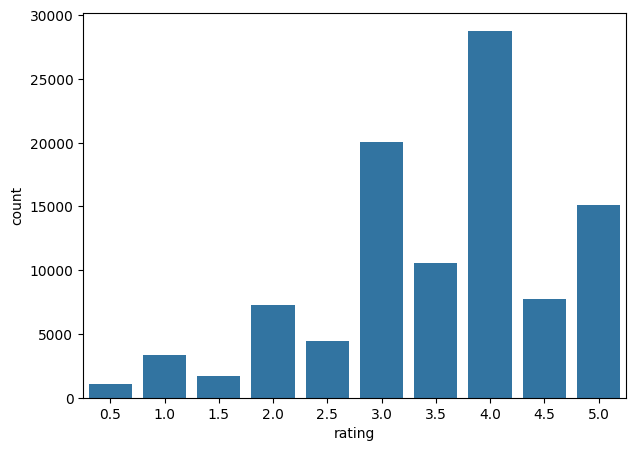

In [29]:
plt.figure(figsize=(7,5))
sns.countplot(data=ratings, x='rating')

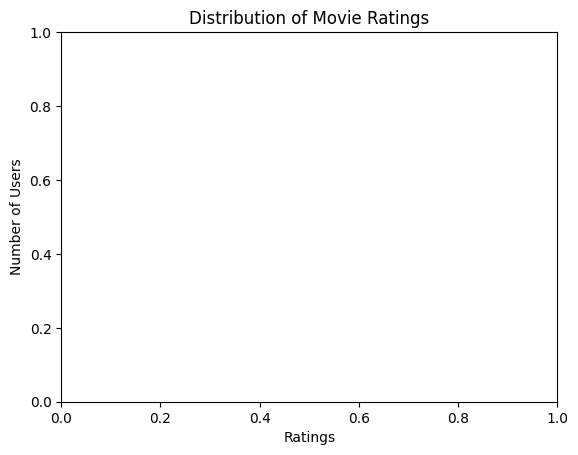

In [30]:
plt.title("Distribution of Movie Ratings")
plt.xlabel("Ratings")
plt.ylabel("Number of Users")

plt.show()

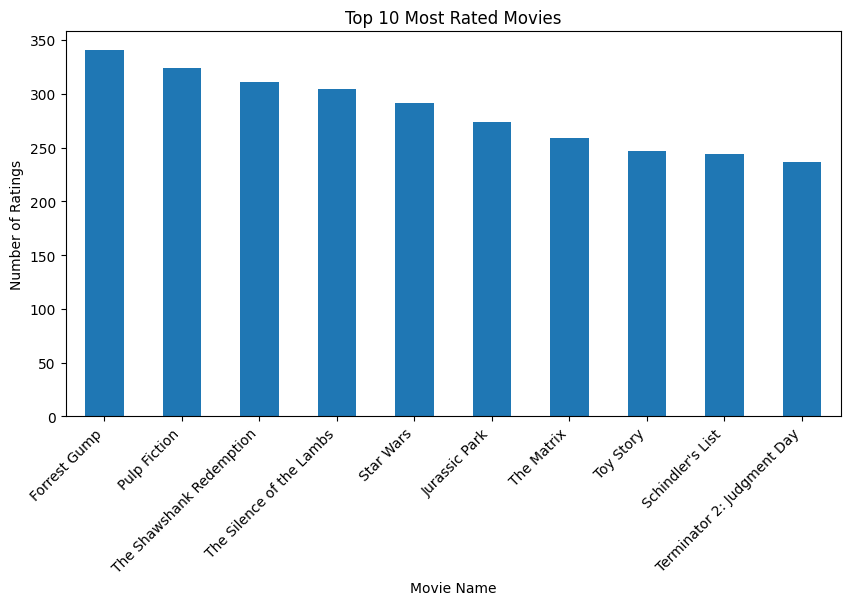

In [31]:
top_movies = merged.groupby('title')['rating'].count()
top_movies = top_movies.sort_values(ascending=False).head(10)

top_movies.plot(kind='bar', figsize=(10,5))

plt.title("Top 10 Most Rated Movies")
plt.xlabel("Movie Name")
plt.ylabel("Number of Ratings")
plt.xticks(rotation=45, ha='right')

plt.show()

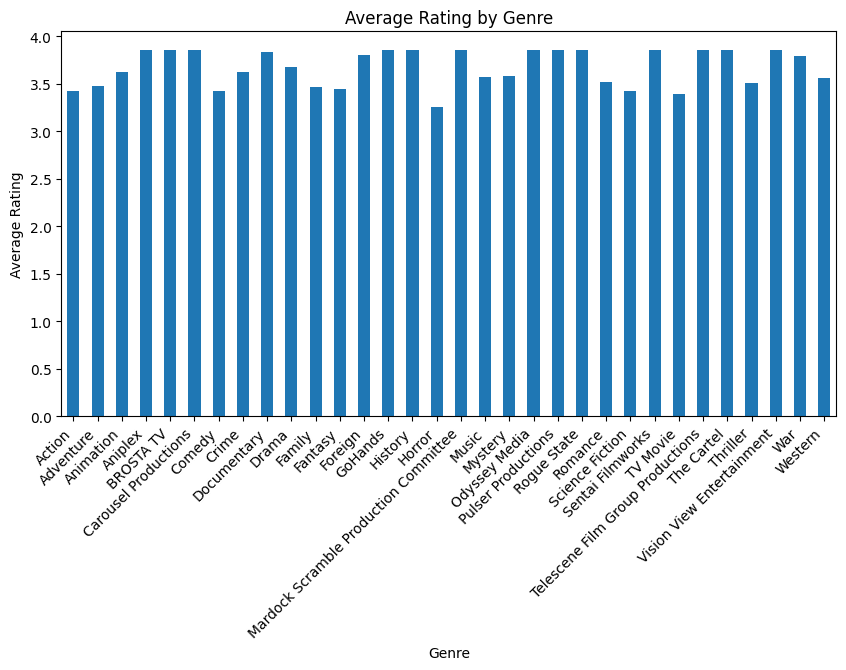

In [32]:
def get_genres(value):
    try:
        return [g['name'] for g in ast.literal_eval(value)]
    except:
        return []

genre_data = merged[['rating', 'genres']].dropna().copy()

genre_data['genres'] = genre_data['genres'].apply(get_genres)
genre_data = genre_data.explode('genres')

genre_avg = genre_data.groupby('genres')['rating'].mean()

genre_avg.plot(kind='bar', figsize=(10,5))

plt.title("Average Rating by Genre")
plt.xlabel("Genre")
plt.ylabel("Average Rating")
plt.xticks(rotation=45, ha='right')

plt.show()

In [33]:
user_ratings = ratings.groupby('userId').size()

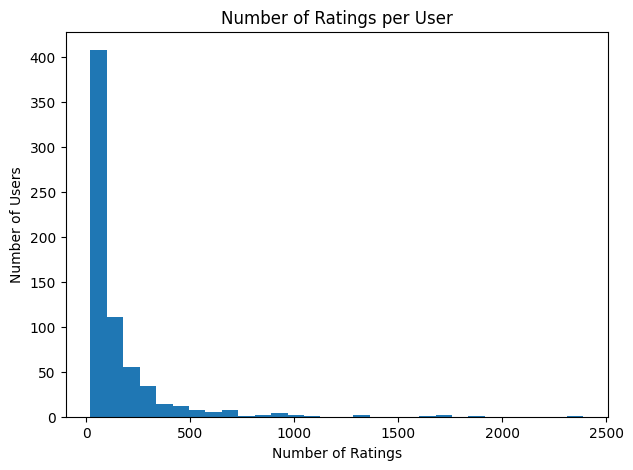

In [34]:
plt.figure(figsize=(7,5))
plt.hist(user_ratings, bins=30)

plt.title("Number of Ratings per User")
plt.xlabel("Number of Ratings")
plt.ylabel("Number of Users")

plt.show()

In [36]:
X = ratings[['userId', 'movieId']]
y = ratings['rating']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [37]:
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Model trained successfully!")

Model trained successfully!


In [38]:
mae = mean_absolute_error(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, predictions)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 0.822325633718314
MSE: 1.1409768724063796
RMSE: 1.0681651896623385
R2 Score: -0.015363382531738523


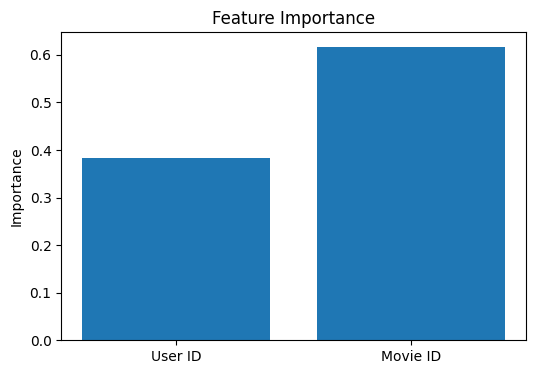

In [39]:
plt.figure(figsize=(6,4))

plt.bar(
    ['User ID', 'Movie ID'],
    model.feature_importances_
)

plt.title("Feature Importance")
plt.ylabel("Importance")

plt.show()